In [25]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.read_csv('../01 - DataPreparation/df_prepared.csv')

In [26]:
feature_columns = [
    'GameWeight', 'MinPlayers', 'MaxPlayers_log',
    'Kickstarted', 'Cat:Thematic', 'Cat:Strategy',
    'Cat:War', 'Cat:Family', 'Cat:CGS', 'Cat:Abstract', 'Cat:Party',
    'Cat:Childrens', 
    'Age',
    'NumOwned_log', 'NumAlternates_log', 'NumExpansions_log',
    'NumImplementations_log'
]

X = df[feature_columns]
y = df['Rating']

In [27]:
le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.3, random_state=42, stratify=y_enc
)

In [28]:
bin_cols = ['Kickstarted'] + [c for c in feature_columns if c.startswith("Cat:")]
num_cols = [c for c in feature_columns if c not in bin_cols]

pre = ColumnTransformer([
    ("num", KBinsDiscretizer(encode="ordinal"), num_cols),
    ("bin", "passthrough", bin_cols),
])

pipe = Pipeline([
    ("pre", pre),
    ("clf", CategoricalNB()),
])

In [29]:

param_grid = {
    "pre__num__strategy": ["uniform"],
    "pre__num__n_bins": [4, 5, 6, 7,8 ,9 , 10, 11, 12, 13],
    "clf__alpha": [0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
    "clf__fit_prior": [True, False],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(pipe, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV F1-Score:", round(grid.best_score_, 3))


Best Parameters: {'clf__alpha': 0.1, 'clf__fit_prior': True, 'pre__num__n_bins': 12, 'pre__num__strategy': 'uniform'}
Best CV F1-Score: 0.616


The categorical (Multinomial) Naive Bayes tuning chose light smoothing (alpha=0.1) with priors learned from the data, and the numeric features were binned into 12 uniform bins. This setup reaches a CV macro-F1 of ~0.616.

In [30]:
best_gnb = grid.best_estimator_
y_pred_train = best_gnb.predict(X_train)
y_pred_test = best_gnb.predict(X_test)

print(f"\nTrain accuracy: {accuracy_score(y_train, y_pred_train):.3f}")
print(f"Test accuracy:  {accuracy_score(y_test, y_pred_test):.3f}")

y_test_dec = le.inverse_transform(y_test)
y_pred_test_dec = le.inverse_transform(y_pred_test)

print("\nConfusion Matrix (Test Set):\n",
      confusion_matrix(y_test_dec, y_pred_test_dec, labels=le.classes_))
print("\nClassification Report (Test Set):\n",
      classification_report(y_test_dec, y_pred_test_dec))



Train accuracy: 0.617
Test accuracy:  0.601

Confusion Matrix (Test Set):
 [[ 839   65  530]
 [  59 1286  639]
 [ 444  723 1587]]

Classification Report (Test Set):
               precision    recall  f1-score   support

        High       0.63      0.59      0.60      1434
         Low       0.62      0.65      0.63      1984
      Medium       0.58      0.58      0.58      2754

    accuracy                           0.60      6172
   macro avg       0.61      0.60      0.60      6172
weighted avg       0.60      0.60      0.60      6172



Categorical Naive Bayes shows moderate, fairly stable performance (train 0.617, test 0.601) with balanced but lower metrics across classes (macro-F1 ~0.60). Most errors are High→Medium and Medium<->Low, meaning the model still struggles to cleanly separate Medium from the other two classes.

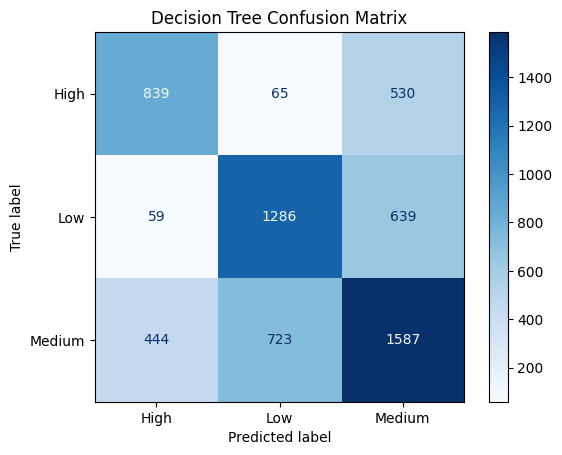

In [31]:
# Confusion matrix as a heatmap
cm = confusion_matrix(y_test, y_pred_test, labels=best_gnb.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.inverse_transform(best_gnb.classes_))
disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()


The confusion matrix shows decent correct predictions on Low (1286) and Medium (1587), but the model often shifts toward Medium: many High -> Medium (530) and Low -> Medium (639) errors. Medium is also frequently confused with Low (723) and High (444), while direct High <-> Low confusion remains relatively small.

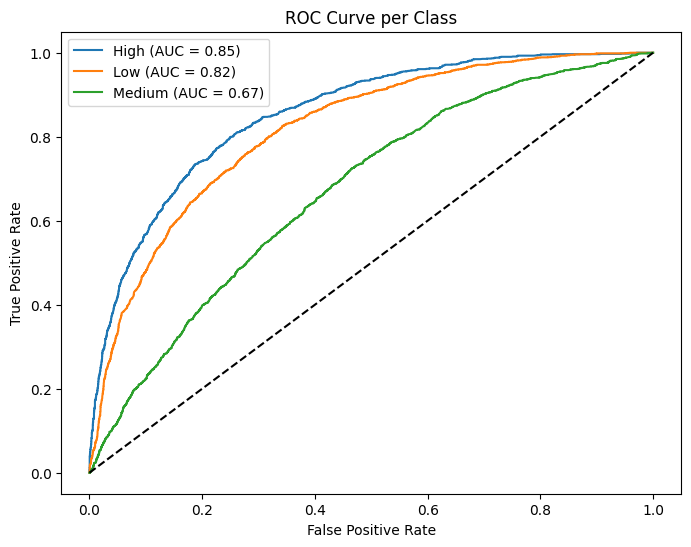

In [32]:
y_bin = label_binarize(y_test, classes=best_gnb.classes_)
y_score = best_gnb.predict_proba(X_test)

plt.figure(figsize=(8,6))
for i, class_label in enumerate(best_gnb.classes_):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    plt.plot(fpr, tpr, label=f'{le.inverse_transform(best_gnb.classes_)[i]} (AUC = {auc(fpr, tpr):.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve per Class")
plt.legend()
plt.show()


ROC per class: High (AUC = 0.85) and Low (AUC = 0.82) show good separability, while Medium (AUC = 0.67) is much weaker (closer to random), meaning the model struggles most to distinguish the Medium class.